# 02 — Rotating and evaluating modes without building 𝔇

Notebook 01 built the full Wigner 𝔇 matrices.  A waveform model rarely needs them: what
it needs is either

- **rotated mode weights**, $f'_{\ell m} = \sum_{m'} f_{\ell m'}\,\mathfrak{D}^\ell_{m',m}(R)$, or
- **function values**, $f(R) = \sum_{\ell m} f_{\ell m}\; {}_{s}Y_{\ell m}(R)$, for example the
  strain at an observer's position.

`jw.rotate` and `jw.evaluate` compute these directly from the $H$ wedge.  This notebook
covers:

1. Mode-weight layout, and how the batch shapes of modes and rotors broadcast
2. `rotate`: definition, and checks against the explicit 𝔇 product
3. `evaluate`: on a grid of directions, and at single points
4. Composing rotations instead of rotating modes
5. A toy precessing waveform
6. Why skipping 𝔇 matters for cost
7. Quaternion helpers for use inside `jit`

In [1]:
import time

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import spherical
from spherical import jaxwigner as jw

rng = np.random.default_rng(2026)

def random_modes(shape, ell_max, spin_weight=0):
    n = spherical.Ysize(0, ell_max)
    f = rng.normal(size=shape + (n,)) + 1j * rng.normal(size=shape + (n,))
    f[..., : spherical.Yindex(abs(spin_weight), -abs(spin_weight))] = 0  # no modes with ℓ < |s|
    return f

def random_rotors(n):
    q = rng.normal(size=(n, 4))
    return q / np.linalg.norm(q, axis=-1, keepdims=True)

## 1. Mode weights and broadcasting

Mode weights use the same layout as `spherical.Modes` and `jw.sYlm`, along the last axis:

```
[f(ℓ, m) for ℓ in range(ell_min, ell_max+1) for m in range(-ℓ, ℓ+1)]
```

indexed with `spherical.Yindex(ℓ, m, ell_min)`.  `ell_max` is inferred from the length of
that axis; `ell_min` (default 0) is a static argument.  For gravitational waves, modes
usually start at ℓ = 2: either pass `ell_min=2`, or store zeros for ℓ < 2.

**Broadcasting differs from `spherical.Wigner`.**  The numba methods apply every rotor to
every set of modes.  The JAX functions instead broadcast the batch shapes of the modes
`(..., n_modes)` and the rotors `(..., 4)` against each other, like any NumPy operation:

| modes | rotors | result of `rotate` | meaning |
|---|---|---|---|
| `(T, n)` | `(T, 4)` | `(T, n)` | one rotation per time sample — precession |
| `(n,)` | `(N, 4)` | `(N, n)` | one set of modes, many rotations |
| `(T, 1, n)` | `(1, N, 4)` | `(T, N, n)` | every combination |

In [2]:
ell_max = 8
n_modes = spherical.Ysize(0, ell_max)
f = random_modes((100,), ell_max)
R = random_rotors(100)

print("modes", f.shape, "+ rotors", R.shape, "->", jw.rotate(f, R).shape)
print("modes", f[0].shape, "+ rotors", R.shape, "->", jw.rotate(f[0], R).shape)
print("modes", f[:, None, :].shape, "+ rotors", R[None, :7].shape, "->", jw.rotate(f[:, None, :], R[None, :7]).shape)

modes (100, 81) + rotors (100, 4) -> (100, 81)


modes (81,) + rotors (100, 4) -> (100, 81)


modes (100, 1, 81) + rotors (1, 7, 4) -> (100, 7, 81)


## 2. `rotate`

With $\mathfrak{D}^\ell_{m',m} = d^\ell_{m',m}(\beta)\, z_\alpha^{m'} z_\gamma^{m}$,

$$
f'_{\ell m} = z_\gamma^{m} \sum_{m'} \left(f_{\ell m'}\, z_\alpha^{m'}\right) d^\ell_{m',m}(\beta),
$$

with $d^\ell$ read directly from the $H$ wedge.  For each ℓ this is written as a broadcast
product followed by a sum, not as a matrix product, so XLA can fuse the lookup from the
wedge into the sum and never store $d^\ell$ in memory.

This matches multiplying by the explicit 𝔇 matrices of notebook 01:

In [3]:
def D_block(D, ell):
    i1, i2 = spherical.WignerDindex(ell, -ell, -ell), spherical.WignerDindex(ell, ell, ell) + 1
    return D[..., i1:i2].reshape(D.shape[:-1] + (2 * ell + 1, 2 * ell + 1))

def mode_block(f, ell):
    return f[..., spherical.Yindex(ell, -ell): spherical.Yindex(ell, ell) + 1]

rotated = jw.rotate(f, R)
D = jw.wigner_D(R, ell_max)
for ell in (2, 5, 8):
    via_D = jnp.einsum("...i,...ij->...j", mode_block(f, ell), D_block(D, ell))
    error = jnp.max(jnp.abs(mode_block(rotated, ell) - via_D))
    norm_change = jnp.max(jnp.abs(jnp.linalg.norm(mode_block(rotated, ell), axis=-1)
                                  - jnp.linalg.norm(mode_block(f, ell), axis=-1)))
    print(f"ℓ={ell}: max |rotate − f·𝔇| = {error:.1e};  max change in |fₗ| = {norm_change:.1e}")

ℓ=2: max |rotate − f·𝔇| = 1.1e-15;  max change in |fₗ| = 4.4e-15


ℓ=5: max |rotate − f·𝔇| = 1.8e-15;  max change in |fₗ| = 8.9e-15


ℓ=8: max |rotate − f·𝔇| = 1.8e-15;  max change in |fₗ| = 1.5e-14


Rotations compose: rotating by $R_1$ and then by $R_2$ equals rotating once by the product
$R_1 R_2$, and rotating by $\bar R$ undoes rotating by $R$.  `jw.multiply` and
`jw.conjugate` provide these operations inside JAX (section 7).

In [4]:
R2 = random_rotors(100)
twice = jw.rotate(jw.rotate(f, R), R2)
once = jw.rotate(f, jw.multiply(R, R2))
undone = jw.rotate(jw.rotate(f, R), jw.conjugate(R))
print("max |rotate twice − rotate by product| =", f"{jnp.max(jnp.abs(twice - once)):.1e}")
print("max |rotate by R then R̄ − original|    =", f"{jnp.max(jnp.abs(undone - f)):.1e}")

max |rotate twice − rotate by product| = 1.2e-14
max |rotate by R then R̄ − original|    = 1.7e-14


## 3. `evaluate`

`jw.evaluate(modes, R, spin_weight)` returns $f(R) = \sum_{\ell m} f_{\ell m}\,{}_{s}Y_{\ell m}(R)$.
For a direction $(\theta, \phi)$ on the sphere, pass the rotor
`jw.from_spherical_coordinates(θ, ϕ)`, which broadcasts its arguments, so a grid of directions
is easy.  Here is a random spin-weight −2 function over the sphere:

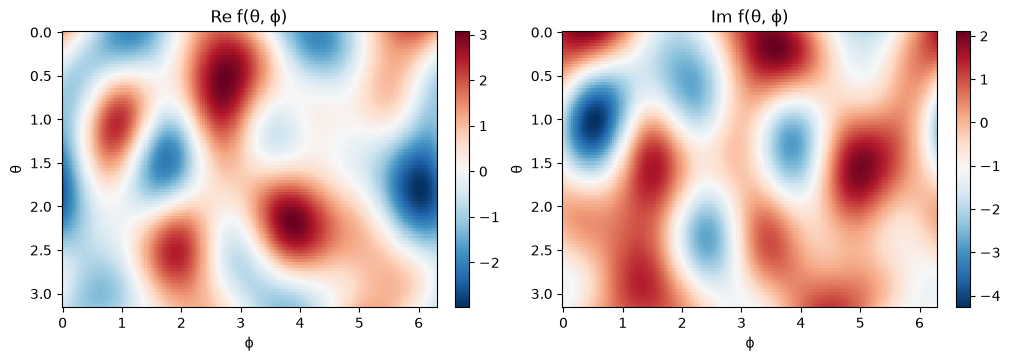

In [5]:
s = -2
f_single = random_modes((), 4, spin_weight=s)
θ = np.linspace(0, np.pi, 91)[:, None]
ϕ = np.linspace(0, 2 * np.pi, 181)[None, :]
values = jw.evaluate(f_single, jw.from_spherical_coordinates(θ, ϕ), s)  # shape (91, 181)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, data, title in zip(axes, (values.real, values.imag), ("Re f(θ, ϕ)", "Im f(θ, ϕ)")):
    im = ax.pcolormesh(ϕ.ravel(), θ.ravel(), data, cmap="RdBu_r", shading="auto")
    ax.set(title=title, xlabel="ϕ", ylabel="θ")
    ax.invert_yaxis()
    fig.colorbar(im, ax=ax)
plt.show()

## 4. Composing rotations instead of rotating modes

Because $\mathfrak{D}(R_1 R_2) = \mathfrak{D}(R_1)\,\mathfrak{D}(R_2)$,

$$
\texttt{evaluate}(\texttt{rotate}(f, R_1),\; R_2) = \texttt{evaluate}(f,\; R_1 R_2).
$$

The left side needs every element of 𝔇: Σ(2ℓ+1)² = 969 terms per rotor for ℓ ≤ 8.  The
right side needs only the 81 harmonics.  For a waveform observed in one direction, the
rotation step can therefore be dropped entirely.

In [6]:
s = -2
f = random_modes((100,), ell_max, spin_weight=s)
R_frame = random_rotors(100)
R_observer = random_rotors(100)

two_steps = jw.evaluate(jw.rotate(f, R_frame), R_observer, s)
one_step = jw.evaluate(f, jw.multiply(R_frame, R_observer), s)
print("max |two steps − one step| =", f"{jnp.max(jnp.abs(two_steps - one_step)):.1e}")

max |two steps − one step| = 1.2e-14


## 5. A toy precessing waveform

This is a **toy** model, only to show the mechanics, not physics:

- In a co-precessing frame, the strain is dominated by the $(2, \pm 2)$ modes, with a slowly
  growing amplitude and a chirping phase, plus a small $(2, \pm 1)$ contribution.
- The frame precesses: its $z$ axis (the orbital angular momentum direction) traces a cone of
  opening angle 0.6 rad around the inertial $z$ axis.  Here
  $R(t) = \texttt{from\_euler\_angles}(\Omega_p t,\; 0.6,\; -\Omega_p t)$.
- An observer sits in the direction $(\theta, \phi) = (1.0, 0.3)$.

The inertial-frame strain at the observer is
$h(t) = \texttt{evaluate}(\texttt{rotate}(h^{\rm cop}(t), R(t)),\, R_{\rm obs})$, or equivalently
$\texttt{evaluate}(h^{\rm cop}(t),\, R(t)\,R_{\rm obs})$.  With the convention used throughout
`spherical`, $h = h_+ - i h_\times$.

**Frame conventions vary between waveform codes.**  Here `rotate(f, R)` gives the mode
weights in the frame rotated by $R$, exactly as `spherical.Wigner.rotate` does.  If your model
defines the co-precessing frame by the opposite rotation, use `jw.conjugate(R)`.  Check
this against a known waveform before relying on it.

max |two steps − one step| = 3.0e-15


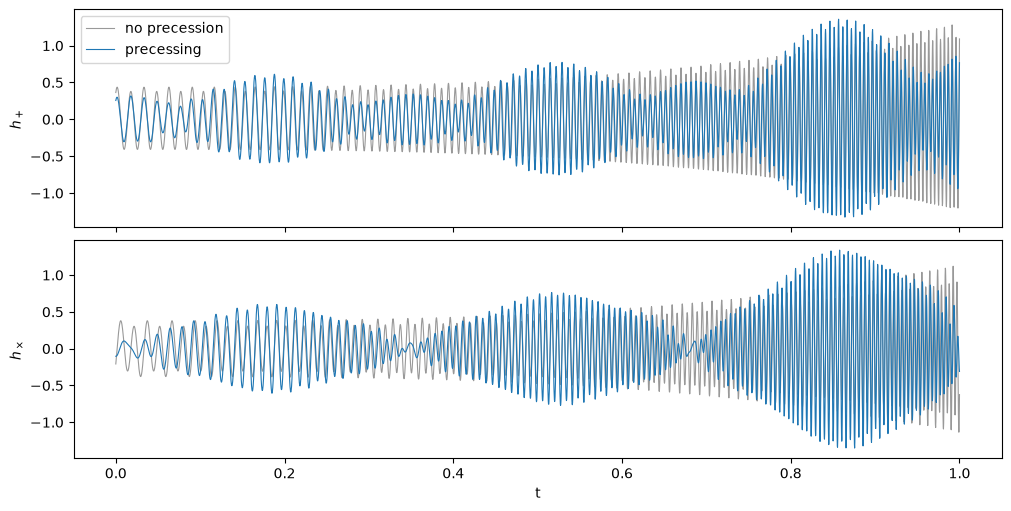

In [7]:
T = 4000
t = np.linspace(0, 1, T)
ell_max_gw = 2
Φ = 2 * np.pi * (30 * t + 40 * t**2)  # chirping orbital phase
A = 1 + 2 * t**3                         # slowly growing amplitude

h_cop = np.zeros((T, spherical.Ysize(0, ell_max_gw)), dtype=complex)
h_cop[:, spherical.Yindex(2, 2)] = A * np.exp(-2j * Φ)
h_cop[:, spherical.Yindex(2, -2)] = A * np.exp(2j * Φ)
h_cop[:, spherical.Yindex(2, 1)] = 0.1 * A * np.exp(-1j * Φ)
h_cop[:, spherical.Yindex(2, -1)] = -0.1 * A * np.exp(1j * Φ)

Ω_p = 2 * np.pi * 3  # precession frequency
R_t = jw.from_euler_angles(Ω_p * t, 0.6, -Ω_p * t)  # shape (T, 4)
R_obs = jw.from_spherical_coordinates(1.0, 0.3)      # shape (4,)

h_two_steps = jw.evaluate(jw.rotate(h_cop, R_t), R_obs, -2)
h_one_step = jw.evaluate(h_cop, jw.multiply(R_t, R_obs), -2)
h_no_precession = jw.evaluate(h_cop, R_obs, -2)
print("max |two steps − one step| =", f"{jnp.max(jnp.abs(h_two_steps - h_one_step)):.1e}")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, constrained_layout=True)
axes[0].plot(t, h_no_precession.real, lw=0.8, color="0.6", label="no precession")
axes[0].plot(t, h_one_step.real, lw=0.8, label="precessing")
axes[0].set(ylabel=r"$h_+$")
axes[0].legend(loc="upper left")
axes[1].plot(t, -h_no_precession.imag, lw=0.8, color="0.6")
axes[1].plot(t, -h_one_step.imag, lw=0.8)
axes[1].set(ylabel=r"$h_\times$", xlabel="t")
plt.show()

In a parameter-estimation or population setting, the same computation runs for many
parameter samples at once.  Everything here broadcasts, so a batch of $S$ samples is just
arrays with a leading axis of length $S$, or the single-sample function wrapped in
`jax.vmap`.  The whole model can be compiled with `jax.jit`:

In [8]:
@jax.jit
def strain_at_observer(h_cop, R_t, θ, ϕ):
    # Inertial-frame strain at (θ, ϕ), for co-precessing modes h_cop of shape (..., T, n)
    R_obs = jw.from_spherical_coordinates(θ, ϕ)
    return jw.evaluate(h_cop, jw.multiply(R_t, R_obs[..., None, :]), -2)

S = 64
θs, ϕs = rng.uniform(0, np.pi, S), rng.uniform(0, 2 * np.pi, S)
h_batch = strain_at_observer(jnp.broadcast_to(h_cop, (S,) + h_cop.shape), R_t, θs, ϕs)
print("batch of strains:", h_batch.shape)
print("sample 0 matches a direct call:",
      bool(jnp.allclose(h_batch[0], jw.evaluate(h_cop, jw.multiply(R_t, jw.from_spherical_coordinates(θs[0], ϕs[0])), -2))))

batch of strains: (64, 4000)


sample 0 matches a direct call: True


## 6. Why skipping 𝔇 matters

The table counts complex numbers per rotor for ℓ ≤ 8:

| quantity | per rotor |
|---|---|
| full 𝔇 | Σ(2ℓ+1)² = 969 |
| mode weights / harmonics | Σ(2ℓ+1) = 81 |

Below, `rotate` and `evaluate` are compared with versions that first build 𝔇 or the
harmonics as separate arrays.  **These are CPU timings on a laptop, for illustration only.**
On a GPU, runtime is set mainly by memory traffic, and the relative costs will differ;
measuring them on a GPU is a later stage.

In [9]:
ell_max = 8
blocks = [(slice(spherical.Yindex(l, -l), spherical.Yindex(l, l) + 1),
           slice(spherical.WignerDindex(l, -l, -l), spherical.WignerDindex(l, l, l) + 1), l)
          for l in range(ell_max + 1)]

@jax.jit
def rotate_via_D(f, R):
    D = jw.wigner_D(R, ell_max)
    return jnp.concatenate([
        jnp.einsum("...i,...ij->...j", f[..., a], D[..., b].reshape(D.shape[:-1] + (2 * l + 1, 2 * l + 1)))
        for a, b, l in blocks
    ], axis=-1)

@jax.jit
def evaluate_via_sYlm(f, R):
    return jnp.sum(f * jw.sYlm(-2, R, ell_max), axis=-1)

evaluate_direct = jax.jit(lambda f, R: jw.evaluate(f, R, -2))

def timed(fn, *args, repeat=3):
    fn(*args).block_until_ready()  # compile first
    start = time.perf_counter()
    for _ in range(repeat):
        fn(*args).block_until_ready()
    return (time.perf_counter() - start) / repeat * 1e3

for N in (2_000, 20_000, 100_000):
    R = random_rotors(N)
    f = random_modes((N,), ell_max, spin_weight=-2)
    print(f"N={N:>7}:  rotate {timed(jw.rotate, f, R):7.1f} ms   (via 𝔇: {timed(rotate_via_D, f, R):7.1f} ms)"
          f"   evaluate {timed(evaluate_direct, f, R):6.1f} ms   (via sYlm: {timed(evaluate_via_sYlm, f, R):6.1f} ms)")

N=   2000:  rotate     4.7 ms   (via 𝔇:    18.4 ms)   evaluate    3.2 ms   (via sYlm:    2.7 ms)


N=  20000:  rotate    54.8 ms   (via 𝔇:   375.1 ms)   evaluate   34.7 ms   (via sYlm:   28.7 ms)


N= 100000:  rotate   644.3 ms   (via 𝔇:  3730.5 ms)   evaluate  405.5 ms   (via sYlm:  500.0 ms)


## 7. Quaternion helpers

`quaternionic` cannot be used inside `jax.jit`, so `spherical.jaxwigner` includes the few
quaternion operations a waveform model needs.  All follow the conventions of `quaternionic`,
which the tests check, and all broadcast:

| function | result |
|---|---|
| `jw.multiply(q1, q2)` | product $q_1 q_2$, with $\mathfrak{D}(q_1 q_2) = \mathfrak{D}(q_1)\mathfrak{D}(q_2)$ |
| `jw.conjugate(q)` | $\bar q$, the inverse of a unit quaternion |
| `jw.inverse(q)` | $\bar q / |q|^2$ |
| `jw.from_euler_angles(α, β, γ)` | $e^{\alpha z/2} e^{\beta y/2} e^{\gamma z/2}$ |
| `jw.from_spherical_coordinates(θ, ϕ)` | $e^{\phi z/2} e^{\theta y/2}$ |

## Summary

- `jw.rotate(modes, R, ell_min=0)` gives $f'_{\ell m} = \sum_{m'} f_{\ell m'}\mathfrak{D}^\ell_{m',m}(R)$ without storing 𝔇.
- `jw.evaluate(modes, R, spin_weight, ell_min=0)` gives $\sum f_{\ell m}\,{}_sY_{\ell m}(R)$.
- Batch shapes of modes and rotors **broadcast**, unlike in `spherical.Wigner`.
- To observe a rotated function in a given direction, compose the rotors instead of rotating
  the modes: `evaluate(f, multiply(R_frame, R_observer), s)`.

Next: gradients with respect to the rotation and the observer direction, including at the
poles.